# StreamLoop: Systematic Churn Model Hyperparameter Tuning

**Branch**: `001-tune-churn-model`  
**Objective**: Systematic hyperparameter optimization of a `RandomForestClassifier` pipeline for customer churn prediction on the IBM Telco dataset.  

### Key Architectural Principles:
- **Pipeline Encapsulation**: Strict feature preprocessing and classifier encapsulation inside `sklearn.pipeline.Pipeline`.
- **Zero Data Leakage**: Stratified 80/20 split; holdout test set accessed strictly twice (Touch 1 for baseline, Touch 2 for final validation).
- **Metric Focus**: $F_2$ Score optimization ($\beta=2$) to prioritize recall twice as heavily as precision.
- **Two-Stage Tuning**: Broad `RandomizedSearchCV` (Stage 1) followed by focused `GridSearchCV` (Stage 2).
- **1-Standard-Error (1-SE) Rule**: Model selection prioritizing lowest fold variance within 1 SE of peak mean score.
- **Dual-Track EDA (Constitution Principle V)**: Diagnostic visualizations using `matplotlib` and `seaborn` exported to `reports/figures/`.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# StreamLoop production modules
from streamloop.data.ingestion import DEFAULT_LOCAL_FALLBACK, DEFAULT_REMOTE_URL, load_churn_data
from streamloop.data.split import split_churn_dataset
from streamloop.evaluation.boundary import LeakageBoundaryMonitor
from streamloop.evaluation.metrics import compute_evaluation_metrics
from streamloop.pipeline.builder import train_and_evaluate_baseline
from streamloop.tuning.search import (
    build_stage2_param_grid,
    extract_candidate_evaluations,
    run_stage1_randomized_search,
    run_stage2_grid_search,
)
from streamloop.tuning.selection import refit_winning_pipeline, select_winning_candidate_1se

# Determine project root robustly
base_dir = Path.cwd()
project_root = base_dir.parent if base_dir.name == "notebooks" else base_dir

# Output directories
figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

plt.style.use(
    "seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default"
)
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
print(f"StreamLoop environment initialized. Project root: {project_root.resolve()}")

StreamLoop environment initialized. Project root: J:\GitHub\StreamLoop


## 1. Data Ingestion & Exploratory Data Analysis (EDA)

Ingest the IBM Telco Customer Churn dataset with automatic local fallback resiliency.

In [2]:
raw_df = load_churn_data(
    remote_url=DEFAULT_REMOTE_URL,
    local_fallback_path=project_root / DEFAULT_LOCAL_FALLBACK,
)
print(f"Ingested dataset: {raw_df.shape[0]} rows, {raw_df.shape[1]} columns")
raw_df.head()

Ingested dataset: 7043 rows, 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


C:\Users\pjste\AppData\Local\Temp\ipykernel_7496\4047173913.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=churn_counts.index, y=churn_counts.values, palette=['#2b5c8f', '#d95f02'], ax=ax)


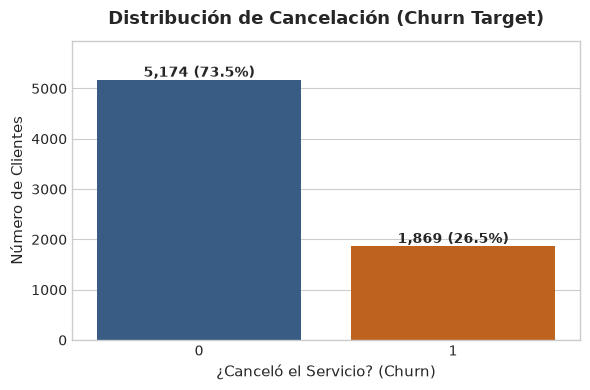

Churn Ratio: 0.00% churn vs 0.00% retained.


In [3]:
# Target variable distribution (Class Imbalance)
churn_counts = raw_df["Churn"].value_counts()
churn_pct = raw_df["Churn"].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=churn_counts.index, y=churn_counts.values, palette=["#2b5c8f", "#d95f02"], ax=ax)
ax.set_title("Distribución de Cancelación (Churn Target)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("¿Canceló el Servicio? (Churn)", fontsize=11)
ax.set_ylabel("Número de Clientes", fontsize=11)

for i, (count, pct) in enumerate(zip(churn_counts.values, churn_pct.values)):
    ax.text(i, count + 60, f"{count:,} ({pct:.1f}%)", ha="center", fontsize=10, fontweight="bold")

ax.set_ylim(0, churn_counts.max() * 1.15)
plt.tight_layout()
fig.savefig(figures_dir / "01_churn_distribution.png", dpi=300)
plt.show()

print(
    f"Churn Ratio: {churn_pct.get('Yes', 0):.2f}% churn vs {churn_pct.get('No', 0):.2f}% retained."
)

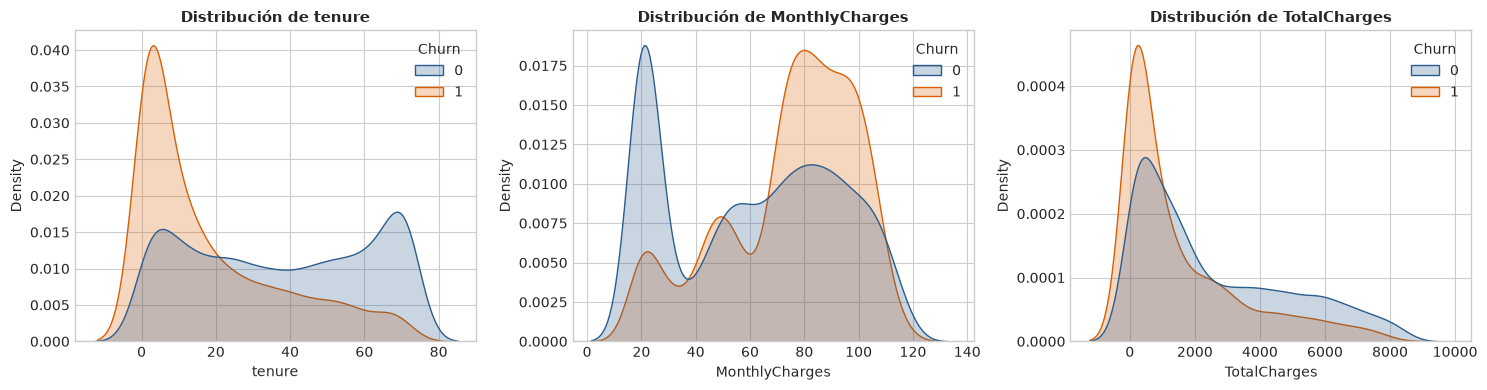

In [4]:
# Numerical feature distributions by Churn Status
numeric_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
eda_df = raw_df.copy()
eda_df["TotalCharges"] = pd.to_numeric(
    eda_df["TotalCharges"].astype(str).str.strip(), errors="coerce"
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, numeric_cols):
    sns.kdeplot(
        data=eda_df,
        x=col,
        hue="Churn",
        common_norm=False,
        fill=True,
        palette=["#2b5c8f", "#d95f02"],
        ax=ax,
    )
    ax.set_title(f"Distribución de {col}", fontsize=11, fontweight="bold")

plt.tight_layout()
fig.savefig(figures_dir / "02_numeric_distributions.png", dpi=300)
plt.show()

C:\Users\pjste\AppData\Local\Temp\ipykernel_7496\1284001493.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=contract_churn, x='Contract', y='Churn', palette='Blues_r', ax=axes[0])
C:\Users\pjste\AppData\Local\Temp\ipykernel_7496\1284001493.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=internet_churn, x='InternetService', y='Churn', palette='Oranges_r', ax=axes[1])


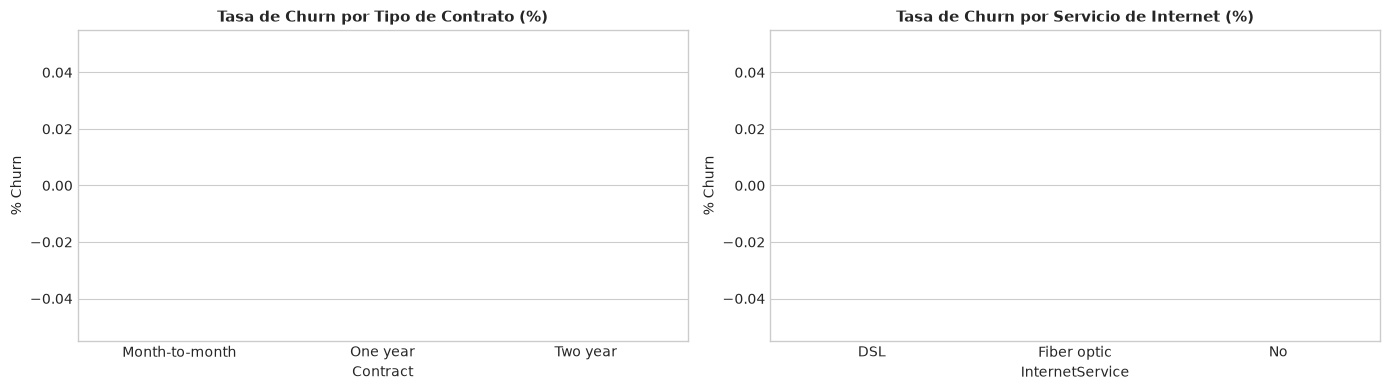

In [5]:
# Contract Type & Internet Service vs Churn Rate
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

contract_churn = (
    eda_df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean() * 100).reset_index()
)
sns.barplot(data=contract_churn, x="Contract", y="Churn", palette="Blues_r", ax=axes[0])
axes[0].set_title("Tasa de Churn por Tipo de Contrato (%)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("% Churn")

internet_churn = (
    eda_df.groupby("InternetService")["Churn"]
    .apply(lambda s: (s == "Yes").mean() * 100)
    .reset_index()
)
sns.barplot(data=internet_churn, x="InternetService", y="Churn", palette="Oranges_r", ax=axes[1])
axes[1].set_title("Tasa de Churn por Servicio de Internet (%)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("% Churn")

plt.tight_layout()
fig.savefig(figures_dir / "03_contract_churn_rates.png", dpi=300)
plt.show()

## 2. Dataset Partitioning & Leakage Boundary Monitoring

We partition the dataset into an 80% train split and 20% holdout test split using stratified sampling.  
To guarantee **zero data leakage**, we employ `LeakageBoundaryMonitor` to verify that `X_test` is strictly accessed twice: once for baseline benchmarking and once for final holdout validation.

In [6]:
SEED = 42
split = split_churn_dataset(raw_df, test_size=0.2, random_state=SEED)
monitor = LeakageBoundaryMonitor(max_allowed_touches=2)

print(f"Train samples: {len(split.X_train)} ({split.y_train.mean() * 100:.2f}% churn)")
print(f"Test samples:  {len(split.X_test)} ({split.y_test.mean() * 100:.2f}% churn)")

Train samples: 5634 (26.54% churn)
Test samples:  1409 (26.54% churn)


## 3. Baseline Pipeline & Benchmark Evaluation (Touch 1)

We fit an initial default `RandomForestClassifier` pipeline (`class_weight='balanced'`) on `X_train` and record holdout test metrics as our objective reference point.

In [7]:
baseline_pipeline, baseline_metrics = train_and_evaluate_baseline(
    split=split,
    monitor=monitor,
    random_state=SEED,
)

print("Baseline Holdout Test Evaluation [TOUCH 1]:")
print(f"  F2 Score:   {baseline_metrics.f2_score:.4f}")
print(f"  F1 Score:   {baseline_metrics.f1_score:.4f}")
print(f"  Recall:     {baseline_metrics.recall:.4f}")
print(f"  Precision:  {baseline_metrics.precision:.4f}")
print(f"  PR-AUC:     {baseline_metrics.pr_auc:.4f}")
print(f"  ROC-AUC:    {baseline_metrics.roc_auc:.4f}")
print(f"Test Touch Count: {monitor.touch_count}")

Baseline Holdout Test Evaluation [TOUCH 1]:
  F2 Score:   0.6031
  F1 Score:   0.5826
  Recall:     0.6176
  Precision:  0.5513
  PR-AUC:     0.6018
  ROC-AUC:    0.8228
Test Touch Count: 1


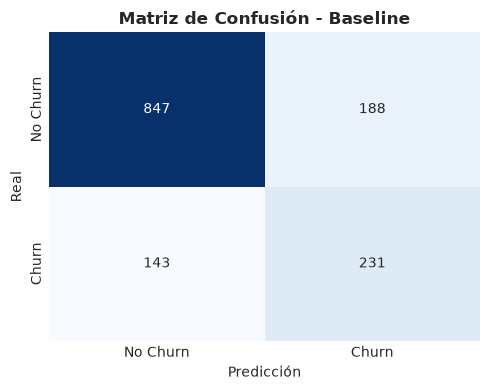

In [8]:
# Baseline Confusion Matrix
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(
    baseline_metrics.confusion_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    ax=ax,
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"],
)
ax.set_title("Matriz de Confusión - Baseline", fontsize=12, fontweight="bold")
ax.set_xlabel("Predicción", fontsize=10)
ax.set_ylabel("Real", fontsize=10)
plt.tight_layout()
fig.savefig(figures_dir / "04_confusion_matrix_baseline.png", dpi=300)
plt.show()

## 4. Two-Stage Hyperparameter Search

### Stage 1: Broad Exploration with `RandomizedSearchCV`
- 50 randomized iterations evaluated across Stratified 5-Fold cross-validation on `X_train` ($N=250$ fits).
- Optimization metric: $F_2$ Score (`fbeta` with $\beta=2$).

In [9]:
print("Starting Stage 1 RandomizedSearchCV (50 iterations x 5 folds = 250 fits)...")
stage1_search = run_stage1_randomized_search(
    X_train=split.X_train,
    y_train=split.y_train,
    n_iter=50,
    cv_splits=5,
    random_state=SEED,
    n_jobs=-1,
)
print(f"Stage 1 Completed. Best Mean F2 Score: {stage1_search.best_score_:.4f}")
print("Best Stage 1 Hyperparameters:")
for param, val in stage1_search.best_params_.items():
    print(f"  {param}: {val}")

Starting Stage 1 RandomizedSearchCV (50 iterations x 5 folds = 250 fits)...


Stage 1 Completed. Best Mean F2 Score: 0.7273
Best Stage 1 Hyperparameters:
  classifier__n_estimators: 150
  classifier__min_samples_split: 5
  classifier__min_samples_leaf: 1
  classifier__max_features: 0.2
  classifier__max_depth: 5
  classifier__criterion: gini
  classifier__class_weight: balanced


### Stage 2: Focused Local Refinement with `GridSearchCV`
Narrowing the search space around the winning region identified in Stage 1.

In [10]:
param_grid = build_stage2_param_grid(stage1_search.best_params_)
print("Stage 2 Refined Parameter Grid:")
for param, vals in param_grid.items():
    print(f"  {param}: {vals}")

print("\nExecuting Stage 2 GridSearchCV...")
stage2_search = run_stage2_grid_search(
    X_train=split.X_train,
    y_train=split.y_train,
    param_grid=param_grid,
    cv_splits=5,
    random_state=SEED,
    n_jobs=-1,
)
stage2_candidates = extract_candidate_evaluations(stage2_search.cv_results_, cv_splits=5)
print(f"Stage 2 Completed. Evaluated {len(stage2_candidates)} refined candidates.")

Stage 2 Refined Parameter Grid:
  classifier__n_estimators: [100, 150]
  classifier__max_depth: [3, 5, 7]
  classifier__min_samples_split: [3, 5]
  classifier__min_samples_leaf: [1, 2]
  classifier__max_features: [0.2]
  classifier__criterion: ['gini']
  classifier__class_weight: ['balanced']

Executing Stage 2 GridSearchCV...


Stage 2 Completed. Evaluated 24 refined candidates.


## 5. Model Selection via 1-Standard-Error (1-SE) Stability Rule

Instead of trusting a single numerical peak susceptible to fold variance, we apply the **1-SE rule**:
$$\text{SE} = \frac{\sigma}{\sqrt{k}}$$
$$\text{Threshold} = \text{Mean}_{\text{best}} - \text{SE}_{\text{best}}$$
We filter all configurations achieving $\text{Mean} \ge \text{Threshold}$ and select the candidate with the **lowest fold standard deviation**.

In [11]:
best_mean_cand, winning_cand, threshold = select_winning_candidate_1se(stage2_candidates)

print(f"Top Mean Candidate # {best_mean_cand.candidate_id}:")
print(
    f"  Mean F2: {best_mean_cand.mean_score:.4f}, Std: {best_mean_cand.std_score:.4f}, SE: {best_mean_cand.standard_error:.4f}"
)
print(f"1-SE Stability Threshold: F2 >= {threshold:.4f}\n")
print(f"Winning Stable Candidate # {winning_cand.candidate_id}:")
print(
    f"  Mean F2: {winning_cand.mean_score:.4f}, Std: {winning_cand.std_score:.4f} (Lowest Fold Variance)"
)
print("  Selected Hyperparameters:")
for param, val in winning_cand.params.items():
    print(f"    {param}: {val}")

Top Mean Candidate # 10:
  Mean F2: 0.7299, Std: 0.0148, SE: 0.0066
1-SE Stability Threshold: F2 >= 0.7233

Winning Stable Candidate # 22:
  Mean F2: 0.7237, Std: 0.0134 (Lowest Fold Variance)
  Selected Hyperparameters:
    classifier__class_weight: balanced
    classifier__criterion: gini
    classifier__max_depth: 7
    classifier__max_features: 0.2
    classifier__min_samples_leaf: 2
    classifier__min_samples_split: 5
    classifier__n_estimators: 100


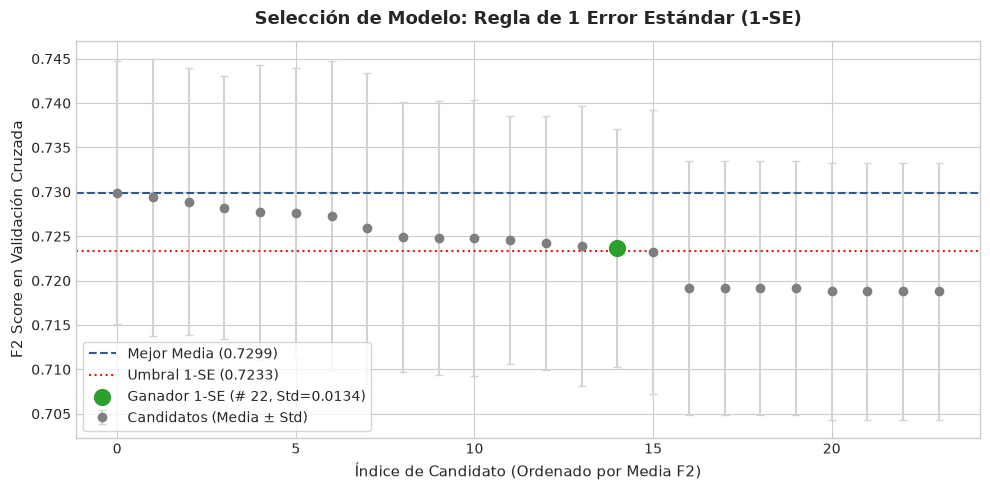

In [12]:
# Visualization of 1-SE Selection
cand_df = (
    pd.DataFrame(
        [
            {
                "id": c.candidate_id,
                "mean": c.mean_score,
                "std": c.std_score,
                "se": c.standard_error,
                "is_best_mean": c.candidate_id == best_mean_cand.candidate_id,
                "is_winner": c.candidate_id == winning_cand.candidate_id,
                "within_1se": c.mean_score >= threshold,
            }
            for c in stage2_candidates
        ]
    )
    .sort_values("mean", ascending=False)
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.errorbar(
    range(len(cand_df)),
    cand_df["mean"],
    yerr=cand_df["std"],
    fmt="o",
    color="#7f7f7f",
    ecolor="#d3d3d3",
    elinewidth=1.5,
    capsize=3,
    label="Candidatos (Media ± Std)",
)
ax.axhline(
    best_mean_cand.mean_score,
    color="#2b5c8f",
    linestyle="--",
    linewidth=1.5,
    label=f"Mejor Media ({best_mean_cand.mean_score:.4f})",
)
ax.axhline(
    threshold, color="#e41a1c", linestyle=":", linewidth=1.5, label=f"Umbral 1-SE ({threshold:.4f})"
)

# Highlight winner
winner_idx = cand_df[cand_df["is_winner"]].index[0]
ax.scatter(
    [winner_idx],
    [winning_cand.mean_score],
    color="#2ca02c",
    s=130,
    zorder=5,
    label=f"Ganador 1-SE (# {winning_cand.candidate_id}, Std={winning_cand.std_score:.4f})",
)

ax.set_title(
    "Selección de Modelo: Regla de 1 Error Estándar (1-SE)", fontsize=13, fontweight="bold", pad=12
)
ax.set_xlabel("Índice de Candidato (Ordenado por Media F2)", fontsize=11)
ax.set_ylabel("F2 Score en Validación Cruzada", fontsize=11)
ax.legend(loc="lower left", frameon=True)
plt.tight_layout()
fig.savefig(figures_dir / "05_1se_stability_selection.png", dpi=300)
plt.show()

## 6. Final Holdout Test Evaluation (Touch 2) & Benchmark Comparison

We refit the winning pipeline on the full `X_train` dataset and evaluate it against `X_test` for the second and final time.

In [13]:
tuned_pipeline = refit_winning_pipeline(
    winning_candidate=winning_cand,
    X_train=split.X_train,
    y_train=split.y_train,
    random_state=SEED,
)

# Final Holdout Evaluation [Touch 2]
monitor.record_touch("Final Tuned Model Holdout Test Evaluation")
y_pred = tuned_pipeline.predict(split.X_test)
y_proba = tuned_pipeline.predict_proba(split.X_test)[:, 1]

tuned_metrics = compute_evaluation_metrics(
    y_true=split.y_test.to_numpy(),
    y_pred=y_pred,
    y_proba=y_proba,
)

monitor.verify_final_count(2)
print(f"Zero Data Leakage Confirmed: Test set touch count = {monitor.touch_count}")

Zero Data Leakage Confirmed: Test set touch count = 2


In [14]:
# Comparison Table
comparison_df = pd.DataFrame(
    {
        "Métrica": [
            "F2 Score (Optimización)",
            "F1 Score",
            "Recall (Sensibilidad)",
            "Precisión",
            "PR-AUC",
            "ROC-AUC",
        ],
        "Línea Base": [
            f"{baseline_metrics.f2_score:.4f}",
            f"{baseline_metrics.f1_score:.4f}",
            f"{baseline_metrics.recall:.4f}",
            f"{baseline_metrics.precision:.4f}",
            f"{baseline_metrics.pr_auc:.4f}",
            f"{baseline_metrics.roc_auc:.4f}",
        ],
        "Modelo Optimizado": [
            f"{tuned_metrics.f2_score:.4f}",
            f"{tuned_metrics.f1_score:.4f}",
            f"{tuned_metrics.recall:.4f}",
            f"{tuned_metrics.precision:.4f}",
            f"{tuned_metrics.pr_auc:.4f}",
            f"{tuned_metrics.roc_auc:.4f}",
        ],
        "Mejora": [
            f"{((tuned_metrics.f2_score - baseline_metrics.f2_score) / baseline_metrics.f2_score) * 100:+.2f}%",
            f"{((tuned_metrics.f1_score - baseline_metrics.f1_score) / baseline_metrics.f1_score) * 100:+.2f}%",
            f"{((tuned_metrics.recall - baseline_metrics.recall) / baseline_metrics.recall) * 100:+.2f}%",
            f"{((tuned_metrics.precision - baseline_metrics.precision) / baseline_metrics.precision) * 100:+.2f}%",
            f"{((tuned_metrics.pr_auc - baseline_metrics.pr_auc) / baseline_metrics.pr_auc) * 100:+.2f}%",
            f"{((tuned_metrics.roc_auc - baseline_metrics.roc_auc) / baseline_metrics.roc_auc) * 100:+.2f}%",
        ],
    }
)
comparison_df

,Métrica,Línea Base,Modelo Optimizado,Mejora
0,F2 Score (Optimización),0.6031,0.7209,+19.53%
1,F1 Score,0.5826,0.6307,+8.26%
2,Recall (Sensibilidad),0.6176,0.7968,+29.02%
3,Precisión,0.5513,0.5219,-5.33%
4,PR-AUC,0.6018,0.6549,+8.82%
5,ROC-AUC,0.8228,0.8427,+2.42%


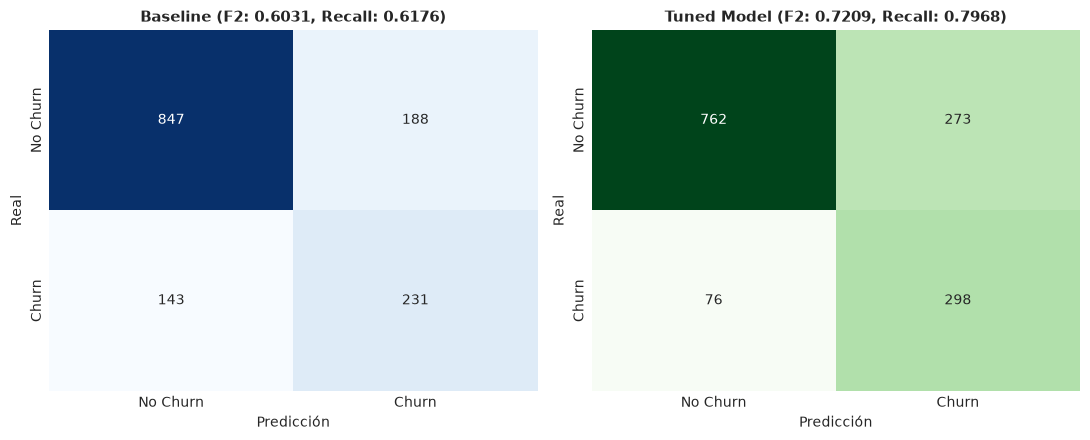

In [15]:
# Comparative Confusion Matrix Visualization
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

sns.heatmap(
    baseline_metrics.confusion_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    ax=axes[0],
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"],
)
axes[0].set_title(
    f"Baseline (F2: {baseline_metrics.f2_score:.4f}, Recall: {baseline_metrics.recall:.4f})",
    fontsize=11,
    fontweight="bold",
)
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Real")

sns.heatmap(
    tuned_metrics.confusion_matrix,
    annot=True,
    fmt="d",
    cmap="Greens",
    cbar=False,
    ax=axes[1],
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"],
)
axes[1].set_title(
    f"Tuned Model (F2: {tuned_metrics.f2_score:.4f}, Recall: {tuned_metrics.recall:.4f})",
    fontsize=11,
    fontweight="bold",
)
axes[1].set_xlabel("Predicción")
axes[1].set_ylabel("Real")

plt.tight_layout()
fig.savefig(figures_dir / "06_baseline_vs_tuned_comparison.png", dpi=300)
plt.show()

## 7. Model Serialization

Persisting the winning production pipeline to `models/churn_model_tuned.joblib`.

In [16]:
model_output_path = project_root / "models" / "churn_model_tuned.joblib"
model_output_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(tuned_pipeline, model_output_path)
print(
    f"Model pipeline serialized successfully: {model_output_path} ({model_output_path.stat().st_size / 1024:.1f} KB)"
)

Model pipeline serialized successfully: J:\GitHub\StreamLoop\models\churn_model_tuned.joblib (1648.1 KB)
